# Laboratorul 2 — Înțelegerea datelor cu Python
**Sisteme bazate pe cunoștințe · Exemple rezolvate: analiza exploratorie a datelor (EDA) privind calitatea vinului roșu**

**Povestea.** Sunteți analistul de date al unei crame. Laboratorul a măsurat 11 proprietăți chimice pentru 1 599 de vinuri roșii *Vinho Verde*, iar o comisie de degustători a acordat fiecărui vin un scor de calitate. Managerul întreabă: **„Ce face un vin bun și putem avea încredere în aceste date?"**

Veți răspunde cu fluxul standard de EDA, pas cu pas:

| pas | întrebare | instrumente |
|---|---|---|
| 1 | Ce conține tabelul? | `shape`, `info`, `describe` |
| 2 | Ne putem baza pe el? | valori lipsă, **duplicate**, valori aberante (outlier) |
| 3 | Cum este distribuită fiecare variabilă? | histograme, asimetrie, boxplot |
| 4 | Cum se leagă două variabile? | corelație, boxplot/violin plot, scatter |
| 5 | Cum interacționează mai multe variabile? | hartă termică (heat-map), pair plot, profiluri de grup |
| 6 | Poate un instrument să facă prima trecere în locul meu? | `fg-data-profiling`, `sweetviz` |

Fiecare pas se încheie cu **🧠 Ce învățăm** – interpretați întotdeauna un grafic în cuvinte. Apoi rezolvați `Lab2_Exercitii.ipynb` pe alte date.

*Setul de date:* P. Cortez et al., *Modeling wine preferences by data mining from physicochemical properties*, 2009 (UCI Machine Learning Repository, Wine Quality). Fișierul `winequality-red.csv` trebuie să se afle lângă acest notebook.

## Pasul 0 — Configurare

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PINK, BLUE, GREY = "#A33573", "#2A7F9E", "#9AA0A6"
pd.set_option("display.precision", 3)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 2.3.3 | numpy 2.3.5 | seaborn 0.13.2


> ⚠️ **Nu scrieți în cod căi absolute** precum `C:\\Users\\...` – codul nu va rula pe alt calculator. Păstrați fișierul CSV lângă notebook și folosiți o cale relativă (suportul de curs folosea o cale personală).

In [2]:
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


## Pasul 1 — Prima privire asupra tabelului
Începeți întotdeauna răspunzând la întrebările: *câte rânduri și coloane are, ce tipuri de date conține, ce intervale de valori?*

In [3]:
print("shape:", df.shape)            # shape este un ATRIBUT: fără paranteze
print("coloane:", df.columns.tolist())
df.info()

shape: (1599, 12)
coloane: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality        

In [4]:
# describe().T este mai ușor de citit când există multe coloane (un rând pe variabilă)
summary = df.describe().T
summary["skew"] = df.skew()
summary["kurtosis"] = df.kurt()
summary["IQR"] = df.quantile(.75) - df.quantile(.25)
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,IQR
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900,0.983,1.132,2.100
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.672,1.226,0.250
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.318,-0.789,0.330
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500,4.541,28.618,0.700
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611,5.680,41.716,0.020
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000,1.251,2.024,14.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000,1.516,3.810,40.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.071,0.934,0.002
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010,0.194,0.807,0.190
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000,2.429,11.720,0.180


🧠 **Ce învățăm**
* 1 599 de rânduri × 12 coloane, fără coloane de text: 11 caracteristici măsurate (`float64`) plus ținta `quality` (`int64`, scoruri întregi de la 3 la 8).
* Comparați *media cu mediana (50 %)*: pentru `residual sugar` (2,54 față de 2,2) și `chlorides` (0,087 față de 0,079) media este trasă în sus de o coadă lungă spre dreapta; maximul lui `residual sugar` este 15,5 – de șapte ori mediana. **Asimetria** (skewness) pozitivă și **boltirea** (kurtosis) mare (cozi grele) confirmă acest lucru.
* Variabilele au scări foarte diferite (`density` ≈ 1, `total sulfur dioxide` până la 289) – important pentru metodele bazate pe distanțe, pe care le vom întâlni mai târziu.

## Pasul 2 — Ne putem baza pe date? Valori lipsă și duplicate

In [5]:
print("valori lipsă pe coloană:")
print(df.isnull().sum().to_string())
print("\ntotal valori lipsă:", int(df.isnull().sum().sum()))

valori lipsă pe coloană:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0

total valori lipsă: 0


Nu există valori lipsă. Acum **duplicatele**. Suportul de curs folosea `df.nunique()` sub titlul *„Verificarea valorilor duplicate"*, dar `nunique()` numără doar *valorile distincte din fiecare coloană* – **nu** detectează *rândurile* duplicate. Instrumentul potrivit este `duplicated()`:

In [6]:
print("valori distincte pe coloană (NU este o verificare a duplicatelor):")
print(df.nunique().to_string())

n_dup = df.duplicated().sum()
print(f"\nrânduri duplicate: {n_dup} din {len(df)}  ({n_dup/len(df):.1%})")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

valori distincte pe coloană (NU este o verificare a duplicatelor):
fixed acidity            96
volatile acidity        143
citric acid              80
residual sugar           91
chlorides               153
free sulfur dioxide      60
total sulfur dioxide    144
density                 436
pH                       89
sulphates                96
alcohol                  65
quality                   6

rânduri duplicate: 240 din 1599  (15.0%)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.992,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.992,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.994,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.994,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.994,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.994,3.72,0.58,11.4,5


🧠 **Ce învățăm:** 240 de rânduri (15 %) sunt copii exacte ale altui rând. Este asta o eroare? În acest set de date poate fi legitim – sticle diferite din același lot, măsurate identic la precizie de 2 zecimale – dar pentru modelare este periculos: rândurile identice ajung atât în setul de antrenare, cât și în cel de testare și fac rezultatele să pară mai bune decât sunt (*scurgere de date*, „data leakage"). Decizia trebuie să fie **explicită și documentată**. Să vedem cât contează:

In [7]:
df_u = df.drop_duplicates().reset_index(drop=True)     # de acum lucrăm cu tabelul fără duplicate
print("rânduri:", len(df), "->", len(df_u))

cmp = pd.DataFrame({
    "cu duplicate": df["quality"].value_counts(normalize=True).sort_index(),
    "fără": df_u["quality"].value_counts(normalize=True).sort_index(),
})
print((cmp * 100).round(1).to_string())
print("\nconținut mediu de alcool:", round(df["alcohol"].mean(), 3), "->", round(df_u["alcohol"].mean(), 3))

rânduri: 1599 -> 1359
         cu duplicate  fără
quality                    
3                 0.6   0.7
4                 3.3   3.9
5                42.6  42.5
6                39.9  39.4
7                12.4  12.3
8                 1.1   1.3

conținut mediu de alcool: 10.423 -> 10.432


Proporțiile claselor și mediile se schimbă foarte puțin, deci eliminarea duplicatelor este sigură aici. **De acum folosim `df_u`** (1 359 de rânduri).

## Pasul 3 — Analiza univariată: câte o variabilă pe rând
### 3.1 Ținta: cum sunt distribuite scorurile?

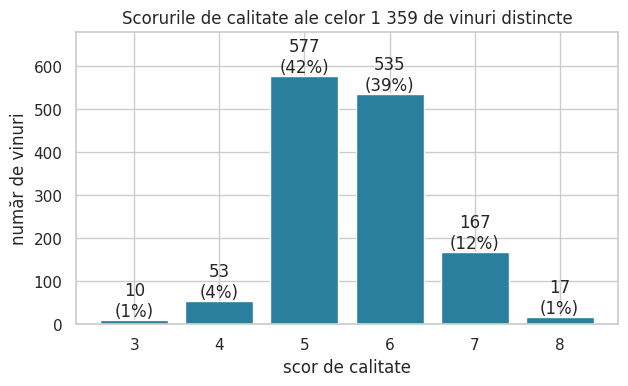

In [8]:
q = df_u["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(q.index.astype(str), q.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v}\n({v/len(df_u):.0%})" for v in q.values])
ax.set(title="Scorurile de calitate ale celor 1 359 de vinuri distincte", xlabel="scor de calitate", ylabel="număr de vinuri")
ax.set_ylim(0, q.max() * 1.18); plt.show()

🧠 **Ce învățăm:** scorurile se concentrează la **5 și 6 (≈ 82 %)**; există doar 10 vinuri cu scorul 3 și 17 cu scorul 8. Ținta este **dezechilibrată**: un model care prezice mereu „5 sau 6" are dreptate în cea mai mare parte a timpului fără să învețe nimic. Vom grupa scorurile în *scăzut (3–4)*, *mediu (5–6)*, *ridicat (7–8)* când avem nevoie de o țintă mai simplă.

In [9]:
df_u["grade"] = pd.cut(df_u["quality"], bins=[0, 4, 6, 10], labels=["scăzută (3-4)", "medie (5-6)", "ridicată (7-8)"])
print(df_u["grade"].value_counts().sort_index().to_string())

grade
scăzută (3-4)       63
medie (5-6)       1112
ridicată (7-8)     184


### 3.2 Distribuția fiecărei caracteristici: histogramă + KDE + asimetrie

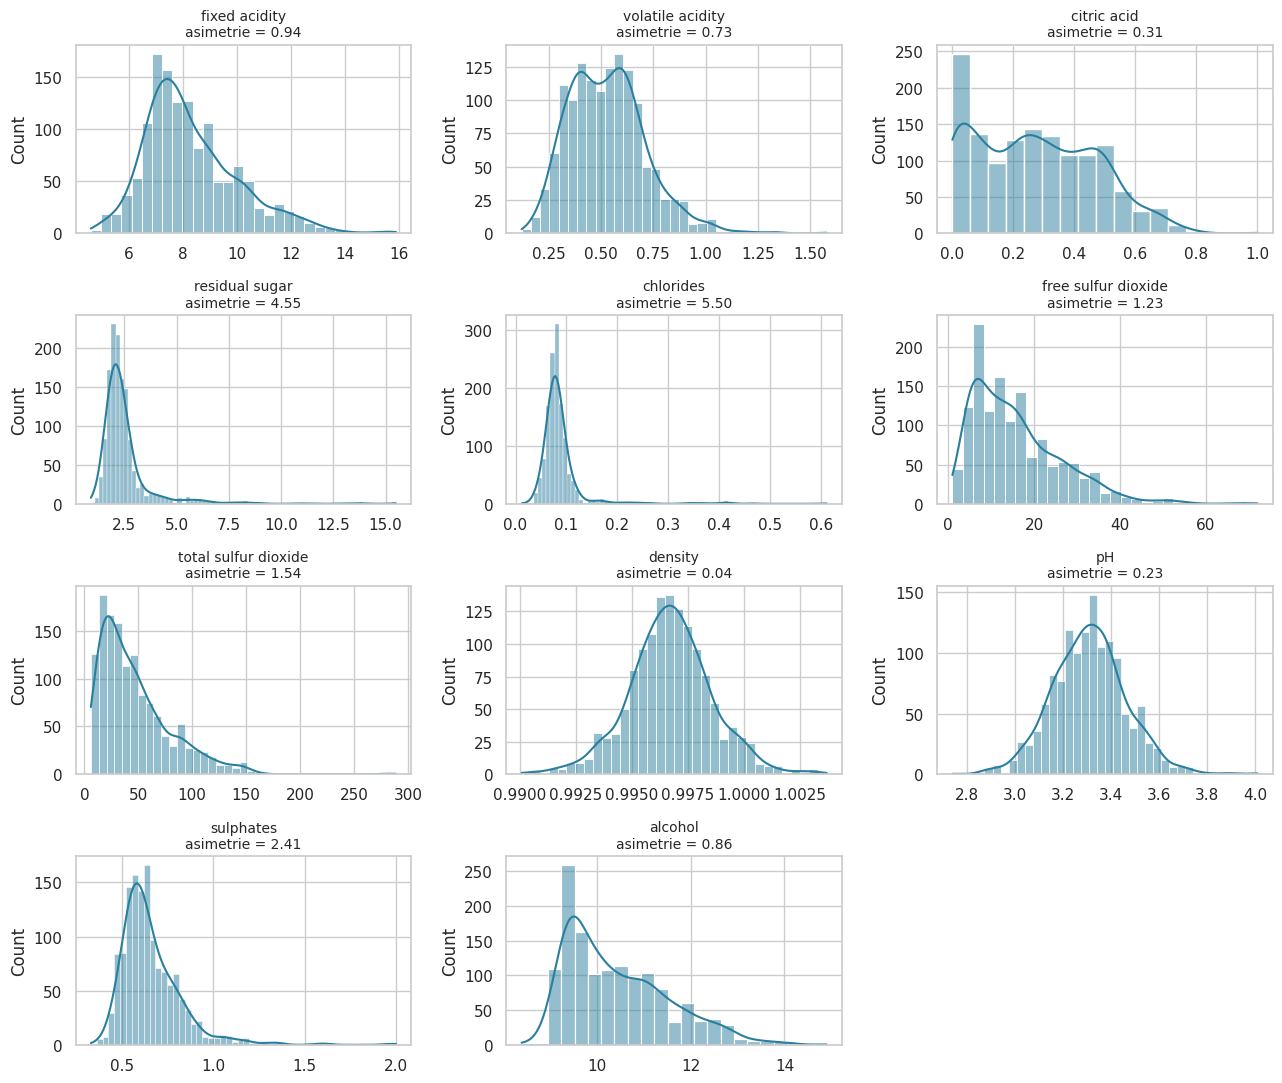

In [10]:
features = df_u.drop(columns=["quality", "grade"]).columns.tolist()

fig, axes = plt.subplots(4, 3, figsize=(13, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df_u[col], kde=True, ax=ax, color=BLUE, edgecolor="white")
    ax.set_title(f"{col}\nasimetrie = {df_u[col].skew():.2f}", fontsize=10); ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Cum se citește asimetria** (`skew`): ≈ 0 simetrică · > 0 coadă lungă spre **dreapta** (puține valori foarte mari) · < 0 coadă lungă spre stânga. Regulă practică: |skew| > 1 înseamnă asimetrie *puternică*.

🧠 **Ce învățăm:** `chlorides` și `residual sugar` sunt extrem de asimetrice spre dreapta (coadă lungă de valori mari); `sulphates`, `total sulfur dioxide` și `free sulfur dioxide` sunt clar asimetrice; `density` și `pH` sunt aproape simetrice (în formă de clopot).

**Corectarea asimetriei** – o transformare logaritmică comprimă coada lungă. Aceasta schimbă *scara*, dar nu ordinea valorilor. Observați cât de mult ajută (sau nu) în fiecare caz:

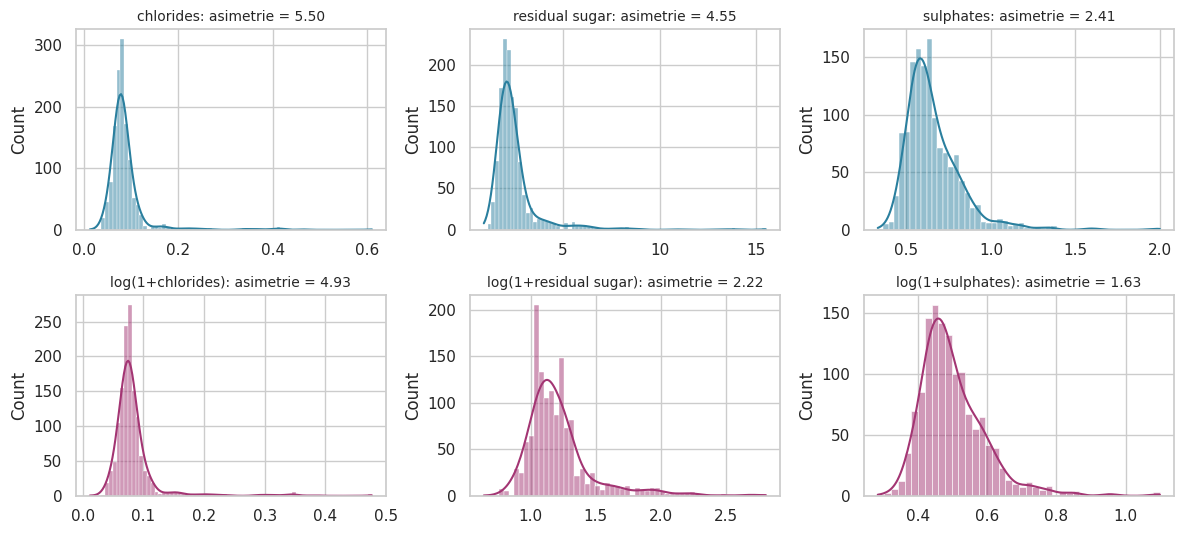

In [11]:
skewed = ["chlorides", "residual sugar", "sulphates"]
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for j, col in enumerate(skewed):
    sns.histplot(df_u[col], kde=True, ax=axes[0, j], color=BLUE, edgecolor="white")
    axes[0, j].set_title(f"{col}: asimetrie = {df_u[col].skew():.2f}", fontsize=10); axes[0, j].set_xlabel("")
    logged = np.log1p(df_u[col])
    sns.histplot(logged, kde=True, ax=axes[1, j], color=PINK, edgecolor="white")
    axes[1, j].set_title(f"log(1+{col}): asimetrie = {logged.skew():.2f}", fontsize=10); axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()

🧠 **Ce învățăm:** transformarea logaritmică funcționează foarte bine pentru `residual sugar` (asimetrie 4,6 → 2,2) și destul de bine pentru `sulphates` (2,4 → 1,6), dar aproape deloc pentru `chlorides` (5,5 → 4,9): câteva valori extreme (până la 0,611) rămân departe de restul. O transformare *reduce* asimetria; ea nu elimină punctele extreme – acestea necesită o decizie separată (pasul următor).

### 3.3 Boxplot și regula IQR: câte valori aberante (outlier) avem?

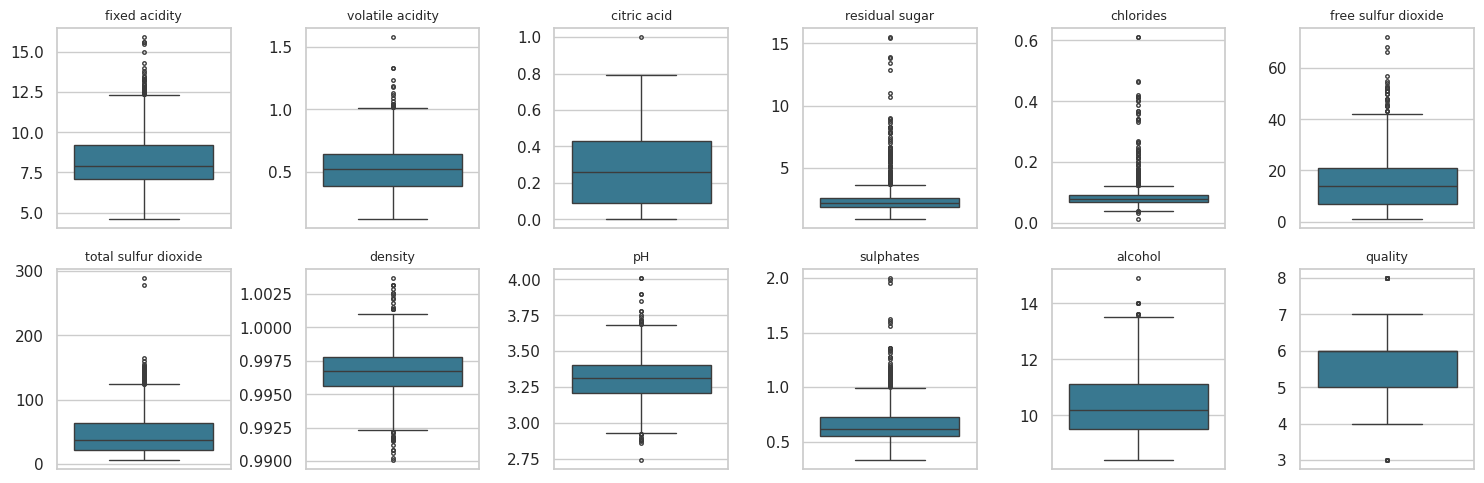

In [12]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, col in zip(axes.ravel(), features + ["quality"]):
    sns.boxplot(y=df_u[col], ax=ax, color=BLUE, fliersize=2.5, linewidth=1)
    ax.set_ylabel(""); ax.set_title(col, fontsize=9)
plt.tight_layout(); plt.show()

Un boxplot marchează ca valori aberante (outlier) punctele aflate dincolo de *mustăți*: **sub Q1 − 1,5·IQR sau peste Q3 + 1,5·IQR** (IQR = Q3 − Q1). Să le numărăm, în loc să ne luăm după aspectul graficului:

In [13]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    return pd.Series({"limita inferioară": lo, "limita superioară": hi,
                      "nr. valori aberante": int(((s < lo) | (s > hi)).sum())})

out = df_u[features].apply(iqr_outliers).T
out["% din rânduri"] = (out["nr. valori aberante"] / len(df_u) * 100).round(1)
out.sort_values("nr. valori aberante", ascending=False).round(3)

,limita inferioară,limita superioară,nr. valori aberante,% din rânduri
residual sugar,0.850,3.650,126.0,9.3
chlorides,0.039,0.122,87.0,6.4
sulphates,0.280,1.000,55.0,4.0
total sulfur dioxide,-39.500,124.500,45.0,3.3
fixed acidity,3.950,12.350,41.0,3.0
density,0.992,1.001,35.0,2.6
pH,2.925,3.685,28.0,2.1
free sulfur dioxide,-14.000,42.000,26.0,1.9
volatile acidity,0.015,1.015,19.0,1.4
alcohol,7.100,13.500,12.0,0.9


🧠 **Ce învățăm:** `residual sugar` (126 de puncte, 9 %) și `chlorides` (87, 6 %) au cele mai multe puncte marcate – exact variabilele puternic asimetrice: într-o distribuție asimetrică „valorile aberante" sunt coada naturală, nu erori. O valoare marcată este doar un **candidat**: înainte de a șterge ceva, întrebați-vă dacă este *posibilă* (sulphates 2,0 g/L este mare, dar plauzibilă), *rară, dar reală* sau o *eroare*. Nimic aici nu este fizic imposibil, așa că păstrăm toate rândurile.

## Pasul 4 — Analiza bivariată: câte două variabile pe rând
### 4.1 Care caracteristici sunt legate de calitate?

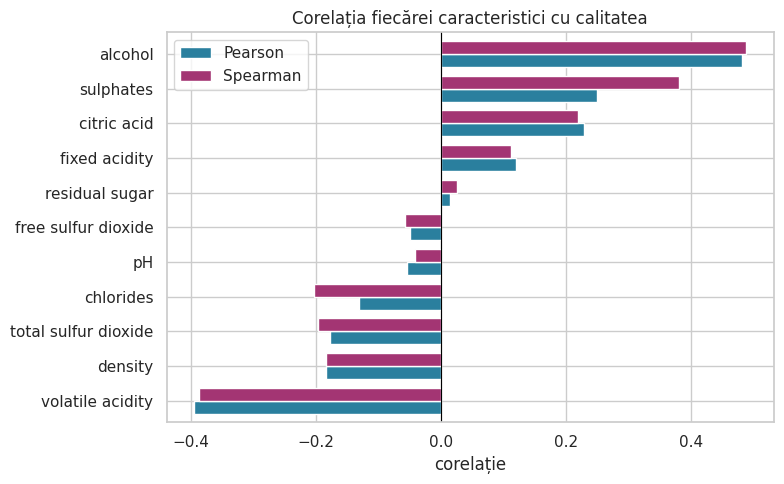

,Pearson,Spearman
volatile acidity,-0.395,-0.387
density,-0.184,-0.184
total sulfur dioxide,-0.178,-0.197
chlorides,-0.131,-0.204
pH,-0.055,-0.043
free sulfur dioxide,-0.050,-0.059
residual sugar,0.014,0.026
fixed acidity,0.119,0.112
citric acid,0.228,0.219
sulphates,0.249,0.381


In [14]:
cor = pd.DataFrame({
    "Pearson":  df_u[features].corrwith(df_u["quality"]),
    "Spearman": df_u[features].corrwith(df_u["quality"], method="spearman"),
}).sort_values("Pearson")

ax = cor.plot.barh(figsize=(8, 5), color=[BLUE, PINK], width=.75)
ax.axvline(0, color="black", lw=.8); ax.set_title("Corelația fiecărei caracteristici cu calitatea"); ax.set_xlabel("corelație")
plt.tight_layout(); plt.show()
cor.round(3)

**Pearson** măsoară asocierea *liniară*, **Spearman** asocierea *rangurilor* (monotonă, robustă la valori aberante și la asimetrie). Dacă cei doi coeficienți sunt de acord, concluzia este solidă.

🧠 **Ce învățăm:** **alcohol** (+0,48) este cel mai puternic corelat pozitiv cu calitatea, **volatile acidity** (−0,40) cel mai puternic corelat negativ (acidul acetic dă un gust de oțet), urmate de sulphates (+0,25), citric acid (+0,23), total sulfur dioxide (−0,18) și density (−0,18). `residual sugar`, `free sulfur dioxide` și `pH` sunt aproape independente de calitate (|r| < 0,06). Observați că, pentru **sulphates** și **chlorides**, Spearman este clar mai mare în valoare absolută decât Pearson (0,38 față de 0,25 și −0,20 față de −0,13): relația este monotonă, dar perturbată de valorile aberante, care afectează mai mult coeficientul Pearson. Țineți minte: **corelația nu înseamnă cauzalitate**, iar chiar și |r| = 0,48 explică doar ≈ 23 % din varianță (r² ≈ 0,23).

### 4.2 Variabilă numerică față de categorie: alcoolul în funcție de scorul de calitate

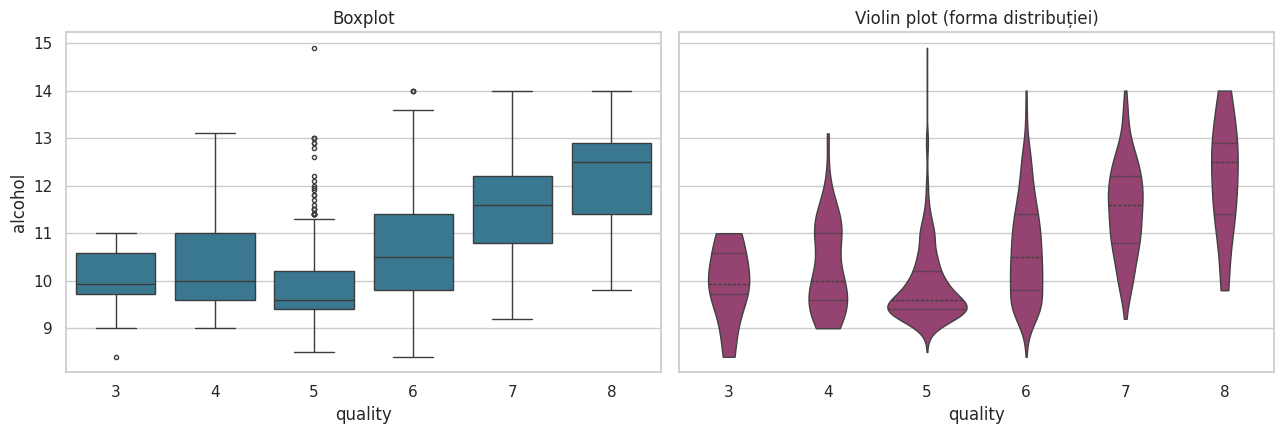

         count  median   mean
quality                      
3           10    9.93   9.96
4           53   10.00  10.27
5          577    9.60   9.89
6          535   10.50  10.66
7          167   11.60  11.49
8           17   12.50  12.16


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sns.boxplot(data=df_u, x="quality", y="alcohol", ax=axes[0], color=BLUE, fliersize=3)
axes[0].set_title("Boxplot")
sns.violinplot(data=df_u, x="quality", y="alcohol", ax=axes[1], color=PINK, inner="quartile", cut=0, linewidth=1)
axes[1].set_title("Violin plot (forma distribuției)")
plt.tight_layout(); plt.show()
print(df_u.groupby("quality")["alcohol"].agg(["count", "median", "mean"]).round(2))

🧠 **Ce învățăm:** începând de la scorul 5, mediana alcoolului crește constant: **9,6 % (scor 5) → 10,5 % (6) → 11,6 % (7) → 12,5 % (8)**. Scorurile foarte rare 3 și 4 (10 și 53 de vinuri) *nu* urmează tendința (mediană ≈ 10 %), deci relația nu este perfect monotonă. Violin plot-ul arată că vinurile cu scorul 5 sunt strâns concentrate în jurul valorii de 9,5 %, cu o coadă superioară lungă (acestea sunt valorile aberante din boxplot), în timp ce vinurile cu scorul 6 sunt larg răspândite între 9 și 14 %: multe vinuri de scor 6 seamănă cu cele de scor 5, iar altele cu cele de scor 7. (Suportul de curs folosea un swarm plot cu 1 599 de puncte – este lent și multe puncte nu pot fi plasate; boxplot-ul și violin plot-ul rezumă mai bine aceeași informație.)

### 4.3 Două variabile numerice: grafice scatter

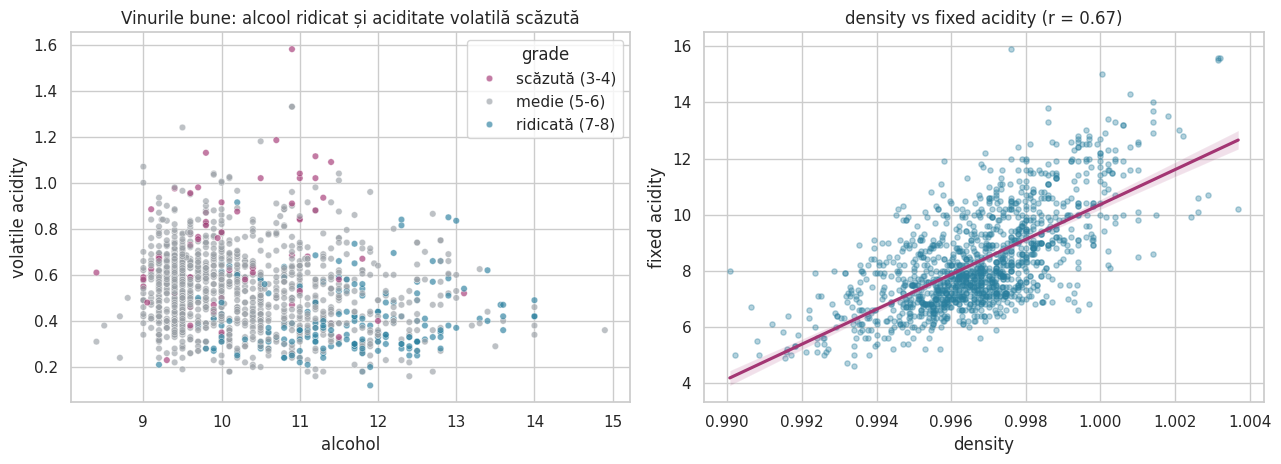

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df_u, x="alcohol", y="volatile acidity", hue="grade", palette=[PINK, GREY, BLUE],
                alpha=.65, s=22, ax=axes[0], hue_order=["scăzută (3-4)", "medie (5-6)", "ridicată (7-8)"])
axes[0].set_title("Vinurile bune: alcool ridicat și aciditate volatilă scăzută")
sns.regplot(data=df_u, x="density", y="fixed acidity", scatter_kws={"alpha": .35, "s": 14, "color": BLUE},
            line_kws={"color": PINK}, ax=axes[1])
axes[1].set_title(f"density vs fixed acidity (r = {df_u['density'].corr(df_u['fixed acidity']):.2f})")
plt.tight_layout(); plt.show()

🧠 **Ce învățăm:** în graficul din stânga, vinurile de calitate ridicată (albastru) se află în **dreapta jos** (alcool peste ~11 %, aciditate volatilă sub ~0,6), în timp ce vinurile de calitate scăzută (roz) se găsesc mai ales **sus** (aciditate volatilă peste ~0,8), la orice nivel de alcool: cele două caracteristici împreună spun mai mult decât fiecare separat, iar grupul mediu (gri) se suprapune peste ambele. În dreapta, `density` și `fixed acidity` au o relație pozitivă puternică (r ≈ 0,67): conțin informație care se suprapune (**multicoliniaritate**).

## Pasul 5 — Analiza multivariată: mai multe variabile deodată
### 5.1 Harta termică (heat-map) a corelațiilor, făcută corect
Matricele complete sunt simetrice, așa că afișați doar triunghiul inferior; folosiți o scară de culori *divergentă*, centrată pe 0, pentru ca semnul să fie vizibil.

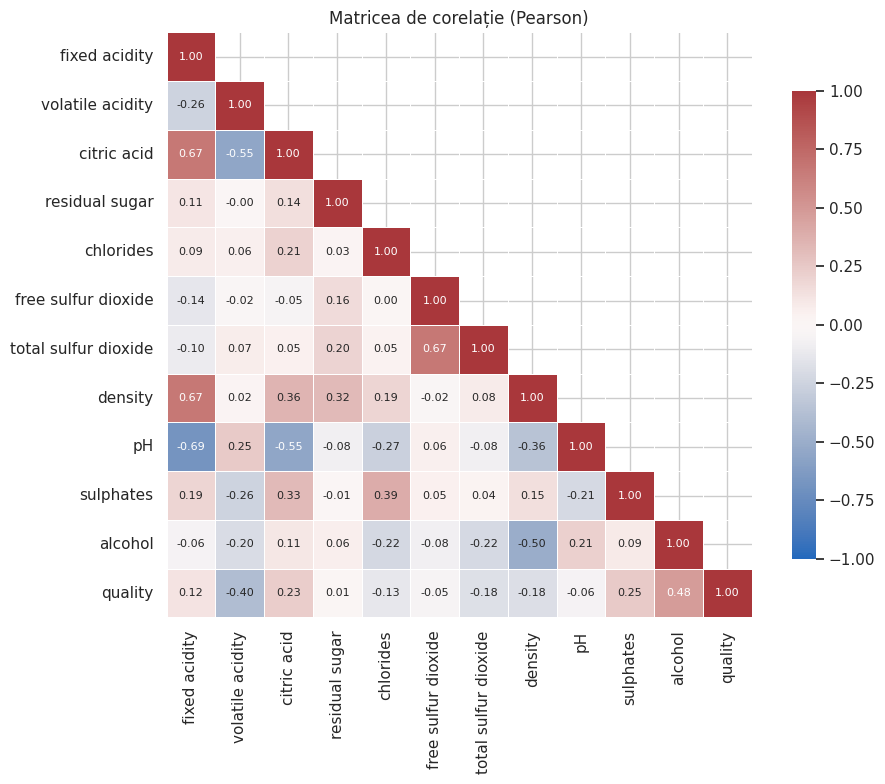

,caracteristica 1,caracteristica 2,r
28,pH,fixed acidity,-0.69
21,density,fixed acidity,0.67
1,citric acid,fixed acidity,0.67
20,total sulfur dioxide,free sulfur dioxide,0.67


In [17]:
corr = df_u[features + ["quality"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot_kws={"size": 8})
plt.title("Matricea de corelație (Pearson)"); plt.tight_layout(); plt.show()

pairs = (corr.where(~mask & (corr != 1)).stack().rename("r").reset_index())
pairs.columns = ["caracteristica 1", "caracteristica 2", "r"]
pairs.loc[pairs["r"].abs() > 0.6].sort_values("r", key=abs, ascending=False).round(2)

🧠 **Ce învățăm:** cele mai puternice perechi sunt **fixed acidity ↔ pH (−0,69)**, **fixed acidity ↔ citric acid (+0,67)**, **fixed acidity ↔ density (+0,67)** și **free ↔ total sulfur dioxide (+0,67)**. Chimic este evident – acizii scad pH-ul – dar este important pentru modelare: intrările puternic corelate fac coeficienții modelelor liniare instabili. (Aici sunt vizibile doar *perechile* de variabile; cazul general se tratează cu PCA în cursurile următoare.)

### 5.2 Pair plot – pe o *selecție* de variabile

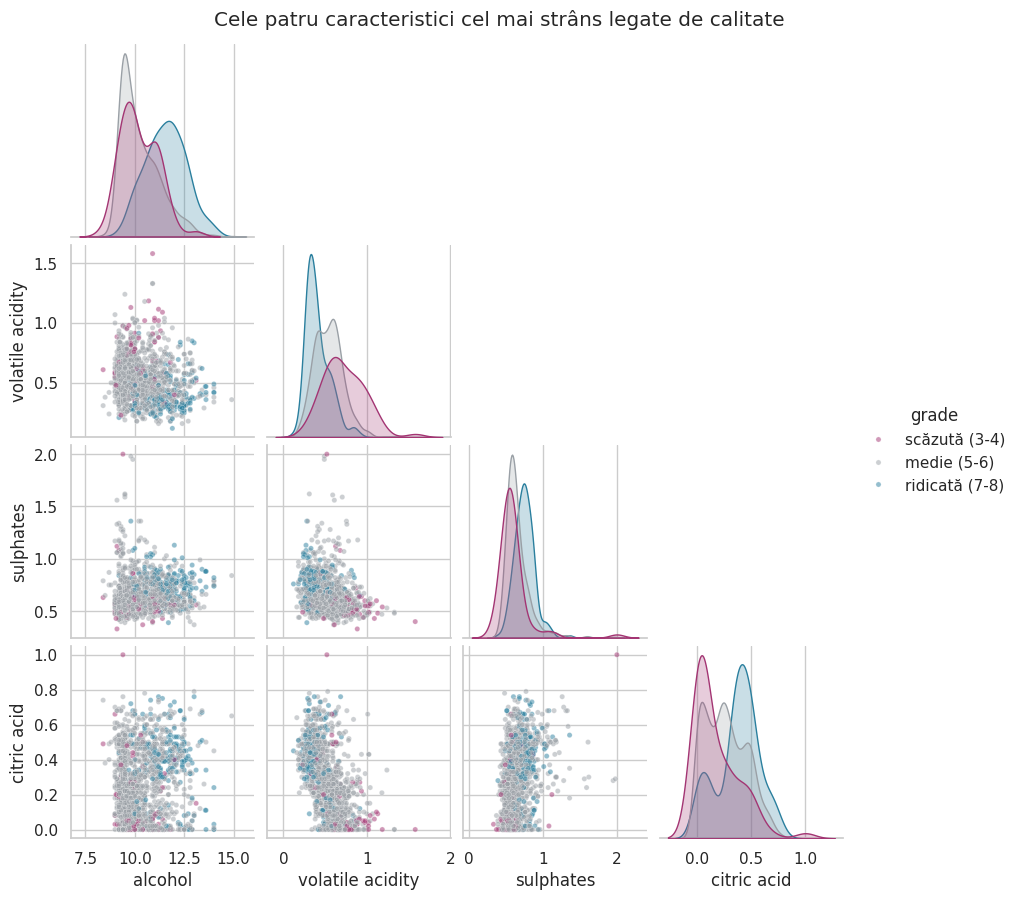

In [18]:
sel = ["alcohol", "volatile acidity", "sulphates", "citric acid"]
g = sns.pairplot(df_u, vars=sel, hue="grade", hue_order=["scăzută (3-4)", "medie (5-6)", "ridicată (7-8)"],
                 palette=[PINK, GREY, BLUE], corner=True, plot_kws={"alpha": .5, "s": 14}, diag_kind="kde", height=2.2, diag_kws={"common_norm": False})
g.figure.suptitle("Cele patru caracteristici cel mai strâns legate de calitate", y=1.02)
plt.show()

Cum se citește: **diagonala** arată distribuția fiecărei variabile (o curbă pentru fiecare grup), iar **celulele** arată fiecare pereche. Cu 12 variabile, un pair plot complet are 144 de panouri și este ilizibil – *selectați* întotdeauna mai întâi variabilele (de exemplu cele mai puternic corelate, găsite în 4.1). 

🧠 **Ce învățăm:** pe diagonală (curba fiecărui grup este normalizată separat, ca să fie vizibile și grupurile mici), curba alcoolului pentru grupul *ridicat* este clar deplasată spre dreapta, iar cea a acidității volatile spre stânga. Nicio caracteristică singură nu separă perfect grupurile – norii de puncte se suprapun – deci clasificarea calității vinului va fi o sarcină imperfectă chiar și cu un model bun.

### 5.3 Profiluri de grup: cum arată un vin tipic de calitate scăzută / medie / ridicată?

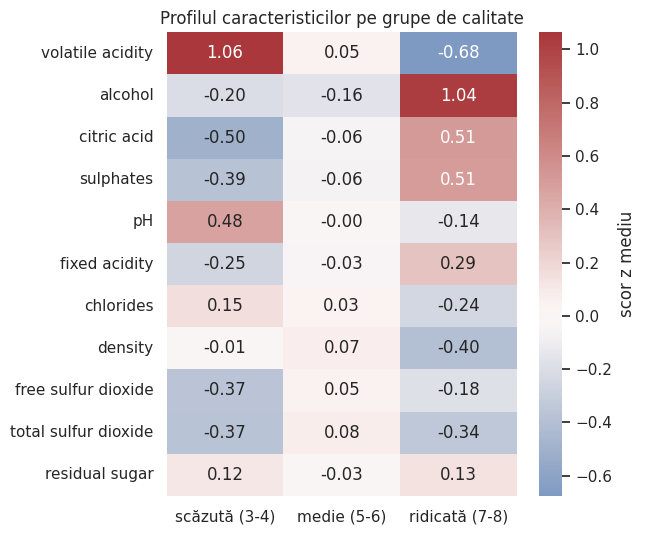

In [19]:
z = (df_u[features] - df_u[features].mean()) / df_u[features].std()          # standardizare: medie 0, abatere standard 1
profile = z.groupby(df_u["grade"], observed=True).mean().T                   # scorul z mediu pe grup
profile = profile.loc[profile["ridicată (7-8)"].sub(profile["scăzută (3-4)"]).abs().sort_values(ascending=False).index]

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(profile, annot=True, fmt=".2f", cmap="vlag", center=0, cbar_kws={"label": "scor z mediu"})
plt.title("Profilul caracteristicilor pe grupe de calitate"); plt.ylabel(""); plt.xlabel(""); plt.tight_layout(); plt.show()

🧠 **Ce învățăm:** citiți tabelul coloană cu coloană (rândurile sunt sortate după cât de mult diferă grupurile ridicat și scăzut). **Vinurile de calitate ridicată** au alcoolul cu +1,0 abateri standard (SD) peste medie, sulphates și citric acid cu aproximativ +0,5 SD, volatile acidity −0,7 SD. **Vinurile de calitate scăzută** se caracterizează în principal prin volatile acidity +1,1 SD, citric acid scăzut (−0,5) și pH mai mare (+0,5) – dar *nu* prin alcool scăzut (doar −0,2). Așadar „bun" înseamnă mai ales *alcool ridicat*, iar „prost" înseamnă mai ales *oțet* (aciditate volatilă). Grupul mediu este, prin construcție, aproape de 0 peste tot. Un singur grafic rezumă întreaga analiză.

## Pasul 6 — Prima trecere automată: rapoarte de profilare
Biblioteci precum **fg-data-profiling** (numită înainte *pandas-profiling*, apoi *ydata-profiling*; se instalează acum cu `pip install fg-data-profiling` și se importă ca `data_profiling`) și **sweetviz** generează un raport EDA complet în HTML – distribuții, valori lipsă, duplicate, corelații, alerte – dintr-o singură linie. Folosiți-le pentru a **începe** o analiză, niciodată pentru a vă înlocui propria interpretare. Instalare, o singură dată: `%pip install fg-data-profiling sweetviz`.

In [20]:
try:
    from data_profiling import ProfileReport              # noul nume al pachetului (fg-data-profiling)
except ImportError:
    try:
        from ydata_profiling import ProfileReport         # numele vechi (nu mai este actualizat)
    except ImportError:
        ProfileReport = None
        print("Nu este instalat -> rulați:  %pip install fg-data-profiling   (apoi reporniți kernelul)")

if ProfileReport is not None:
    report = ProfileReport(df, title="Calitatea vinului roșu", minimal=True, progress_bar=False)   # minimal=True: mod rapid
    report.to_file("raport_vin.html")
    print("raport salvat ca raport_vin.html - deschideți-l într-un browser")
    # În Jupyter îl puteți afișa și direct în notebook:  report.to_notebook_iframe()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/12 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 129.42it/s]

raport salvat ca raport_vin.html - deschideți-l într-un browser


> 💡 Verificați că raportul *concordă* cu ce ați găsit manual: el semnalează cele **240 de rânduri duplicate**, variabilele puternic asimetrice și perechile cu corelație mare. Dacă instalați aceste biblioteci într-o versiune foarte nouă de Python/pandas și importul eșuează, folosiți o versiune de Python acceptată de pachete (vedeți nota de laborator *Cum se creează un mediu virtual cu o altă versiune de Python*).

## Pasul 7 — Raportul de concluzii
O EDA bună se încheie cu *afirmații pe care le poate folosi un manager*, fiecare susținută de un număr. Hai să le generăm din date, în loc să le scriem de mână:

In [21]:
top_pos = cor["Pearson"].idxmax(); top_neg = cor["Pearson"].idxmin()
share_56 = df_u["quality"].isin([5, 6]).mean()
print(f"1. Dimensiunea datelor: {len(df)} rânduri, dintre care {n_dup} ({n_dup/len(df):.0%}) sunt duplicate -> se folosesc {len(df_u)}.")
print("2. Valori lipsă: niciuna.")
print(f"3. Ținta este dezechilibrată: {share_56:.0%} dintre vinuri au scorul 5 sau 6; doar {int((df_u.quality==3).sum())} vinuri au scorul 3.")
print(f"4. Cea mai puternică corelație pozitivă cu calitatea: {top_pos} (r = {cor.loc[top_pos,'Pearson']:+.2f}).")
print(f"5. Cea mai puternică corelație negativă cu calitatea: {top_neg} (r = {cor.loc[top_neg,'Pearson']:+.2f}).")
skew_top = df_u[features].skew().abs().sort_values(ascending=False).head(2)
print(f"6. Cele mai asimetrice variabile: {', '.join(skew_top.index)} (|skew| = {skew_top.iloc[0]:.1f}, {skew_top.iloc[1]:.1f}) -> luați în considerare o transformare logaritmică.")
print(f"7. Intrări corelate: fixed acidity cu pH/density/citric acid -> atenție la multicoliniaritate în modele.")

1. Dimensiunea datelor: 1599 rânduri, dintre care 240 (15%) sunt duplicate -> se folosesc 1359.
2. Valori lipsă: niciuna.
3. Ținta este dezechilibrată: 82% dintre vinuri au scorul 5 sau 6; doar 10 vinuri au scorul 3.
4. Cea mai puternică corelație pozitivă cu calitatea: alcohol (r = +0.48).
5. Cea mai puternică corelație negativă cu calitatea: volatile acidity (r = -0.40).
6. Cele mai asimetrice variabile: chlorides, residual sugar (|skew| = 5.5, 4.5) -> luați în considerare o transformare logaritmică.
7. Intrări corelate: fixed acidity cu pH/density/citric acid -> atenție la multicoliniaritate în modele.


## Recapitulare

| întrebare | instrument | capcană evitată |
|---|---|---|
| dimensiunea tabelului, tipuri | `shape`, `info()`, `describe().T` | `shape` nu are `()` |
| valori lipsă | `isnull().sum()` | – |
| **rânduri** duplicate | `duplicated().sum()`, `drop_duplicates()` | `nunique()` nu verifică duplicatele |
| distribuție | histogramă + KDE, `skew()`, `kurt()` | cozile asimetrice nu sunt automat erori |
| valori aberante (outlier) | boxplot, limite IQR | decideți: eroare, rar-dar-real sau coadă naturală |
| relația cu ținta | `corrwith`, Pearson vs Spearman, boxplot/violin plot | corelație ≠ cauzalitate |
| mai multe variabile | heat-map mascat, pair plot *selectat*, profil de grup | pair plot-uri 12×12 ilizibile |
| raport rapid | `fg-data-profiling`, `sweetviz` | folosiți-l ca punct de plecare, nu ca răspuns |

**Mai multe resurse:** GeeksforGeeks *EDA – Exploratory Data Analysis in Python* https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/ · tutorialul seaborn https://seaborn.pydata.org/tutorial.html · ghidul de utilizare pandas https://pandas.pydata.org/docs/user_guide/index.html

➡️ Urmează: **`Lab2_Exercitii.ipynb`** – același flux de lucru pe datele despre *pinguini* și pe un set de date de tip „smart office" *deliberat corupt*.